In [25]:
import pandas as pd
import numpy as np
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')

df = pd.read_csv('netflix_customer_churn.csv')

df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [26]:
display(df.info())
display(df.columns)
display(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 920.1

None

Index(['customer_id', 'age', 'gender', 'subscription_type', 'watch_hours',
       'last_login_days', 'region', 'device', 'monthly_fee', 'churned',
       'payment_method', 'number_of_profiles', 'avg_watch_time_per_day',
       'favorite_genre'],
      dtype='str')

customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

In [27]:
df.describe().round(2)

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,5000.00,5000.00,5000.00,5000.00,5000.0,5000.00,5000.00
mean,43.85,11.65,30.09,13.68,0.5,3.02,0.87
std,15.50,12.01,17.54,3.69,0.5,1.42,2.62
min,18.00,0.01,0.00,8.99,0.0,1.00,0.00
25%,30.00,3.34,15.00,8.99,0.0,2.00,0.11
50%,44.00,8.00,30.00,13.99,1.0,3.00,0.29
75%,58.00,16.03,45.00,17.99,1.0,4.00,0.72
max,70.00,110.40,60.00,17.99,1.0,5.00,98.42


In [28]:
resumen_calidad = pd.DataFrame({
    "Tipo de dato": df.dtypes.astype(str),
    "Valores nulos": df.isna().sum(),
    "Nulos (%)": (df.isna().mean() * 100).round(2),
    "Valores únicos": df.nunique()
})

# Identificación de posibles cadenas de texto vacías
resumen_calidad["Textos vacíos"] = [
    df[col].astype("string").str.strip().eq("").sum()
    if pd.api.types.is_string_dtype(df[col])
    else 0
    for col in df.columns
]

display(resumen_calidad)

# Comprobación de registros e identificadores
print("Registros totales:", len(df))
print("Filas duplicadas:", df.duplicated().sum())
print("Identificadores duplicados:", df["customer_id"].duplicated().sum())

# Validación de valores fuera de rangos razonables
validaciones = {
    "Edad menor o igual a cero": (df["age"] <= 0).sum(),
    "Horas de visualización negativas": (df["watch_hours"] < 0).sum(),
    "Días desde último acceso negativos": (df["last_login_days"] < 0).sum(),
    "Tarifas mensuales no positivas": (df["monthly_fee"] <= 0).sum(),
    "Número de perfiles menor a uno": (df["number_of_profiles"] < 1).sum(),
    "Promedio diario negativo": (df["avg_watch_time_per_day"] < 0).sum(),
    "Valores de churn diferentes de 0 y 1": (~df["churned"].isin([0, 1])).sum()
}

display(
    pd.DataFrame(
        validaciones.items(),
        columns=["Validación", "Registros detectados"]
    )
)

# Comprobación especial:
# Si avg_watch_time_per_day se expresa en horas por día,
# cualquier valor superior a 24 requiere investigación.

print(
    "Promedios diarios superiores a 24:",
    (df["avg_watch_time_per_day"] > 24).sum()
)

# Nota:
# Las validaciones detectan posibles inconsistencias.
# No se eliminan ni modifican registros automáticamente.


,Tipo de dato,Valores nulos,Nulos (%),Valores únicos,Textos vacíos
customer_id,str,0,0.0,5000,0
age,int64,0,0.0,53,0
gender,str,0,0.0,3,0
subscription_type,str,0,0.0,3,0
watch_hours,float64,0,0.0,2343,0
last_login_days,int64,0,0.0,61,0
region,str,0,0.0,6,0
device,str,0,0.0,5,0
monthly_fee,float64,0,0.0,3,0
churned,int64,0,0.0,2,0


Registros totales: 5000
Filas duplicadas: 0
Identificadores duplicados: 0


,Validación,Registros detectados
0,Edad menor o igual a cero,0
1,Horas de visualización negativas,0
2,Días desde último acceso negativos,0
3,Tarifas mensuales no positivas,0
4,Número de perfiles menor a uno,0
5,Promedio diario negativo,0
6,Valores de churn diferentes de 0 y 1,0


Promedios diarios superiores a 24: 10


,Variable,Límite inferior,Límite superior,Outliers,Porcentaje (%),Valor máximo
0,age,-12.00,100.00,0,0.00,70.00
1,watch_hours,-15.70,35.07,238,4.76,110.40
2,last_login_days,-30.00,90.00,0,0.00,60.00
3,monthly_fee,-4.51,31.49,0,0.00,17.99
4,number_of_profiles,-1.00,7.00,0,0.00,5.00
5,avg_watch_time_per_day,-0.80,1.64,549,10.98,98.42


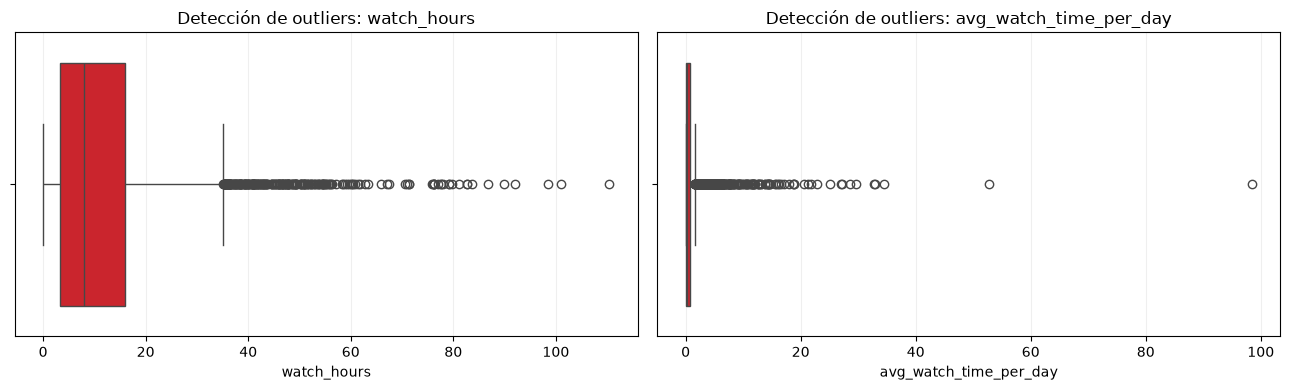

Usuarios con los promedios diarios más elevados:


,customer_id,watch_hours,avg_watch_time_per_day,last_login_days,churned
2017,23e2a122-9e50-41d8-a434-c25675765f79,98.42,98.42,0,0
1219,45ea1095-e06b-4a1c-a0b7-c3671c9f006a,52.80,52.80,0,0
2564,511d9a10-669b-4283-bc6d-40c10a595b43,34.53,34.53,0,0
4792,88a98e69-9e49-4d28-98d7-1e0b1bce6138,32.88,32.88,0,0
4078,9adb0b11-3199-438c-9b3c-59dee22c6b27,32.81,32.81,0,0
4805,b906246e-44aa-441f-85c5-fc2aa946b0cb,29.55,29.55,0,0
3641,64d85f24-42f8-48b1-8675-590db42d23e5,28.66,28.66,0,0
4285,3878e4e3-2960-4b36-b25c-f90ddd01b5d8,54.53,27.27,1,0
4845,d202349e-dd45-42e7-84a9-fa604082763f,26.98,26.98,0,0
647,c350d5a0-fef7-4281-b752-42162d72bd05,25.15,25.15,0,0


In [29]:
columnas_outliers = [
    "age",
    "watch_hours",
    "last_login_days",
    "monthly_fee",
    "number_of_profiles",
    "avg_watch_time_per_day"
]

resultados_outliers = []

for columna in columnas_outliers:

    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    mascara_outliers = (
        (df[columna] < limite_inferior) |
        (df[columna] > limite_superior)
    )

    cantidad = mascara_outliers.sum()

    resultados_outliers.append({
        "Variable": columna,
        "Límite inferior": round(limite_inferior, 2),
        "Límite superior": round(limite_superior, 2),
        "Outliers": cantidad,
        "Porcentaje (%)": round(cantidad / len(df) * 100, 2),
        "Valor máximo": df[columna].max()
    })

tabla_outliers = pd.DataFrame(resultados_outliers)

display(tabla_outliers)

# Visualización de los valores atípicos detectados
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, columna in zip(
    axes,
    ["watch_hours", "avg_watch_time_per_day"]
):
    sns.boxplot(
        x=df[columna],
        color="#E50914",
        showfliers=True,
        ax=ax
    )

    ax.set_title(f"Detección de outliers: {columna}")
    ax.set_xlabel(columna)
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

# Inspección de los registros con mayores valores
print("Usuarios con los promedios diarios más elevados:")

display(
    df.nlargest(10, "avg_watch_time_per_day")[
        [
            "customer_id",
            "watch_hours",
            "avg_watch_time_per_day",
            "last_login_days",
            "churned"
        ]
    ]
)

# Decisión metodológica:
# Conservamos los registros originales.
# Un outlier estadístico no es necesariamente un dato erróneo.
# Los valores incompatibles con la definición de la variable
# deben investigarse antes de decidir cómo tratarlos.


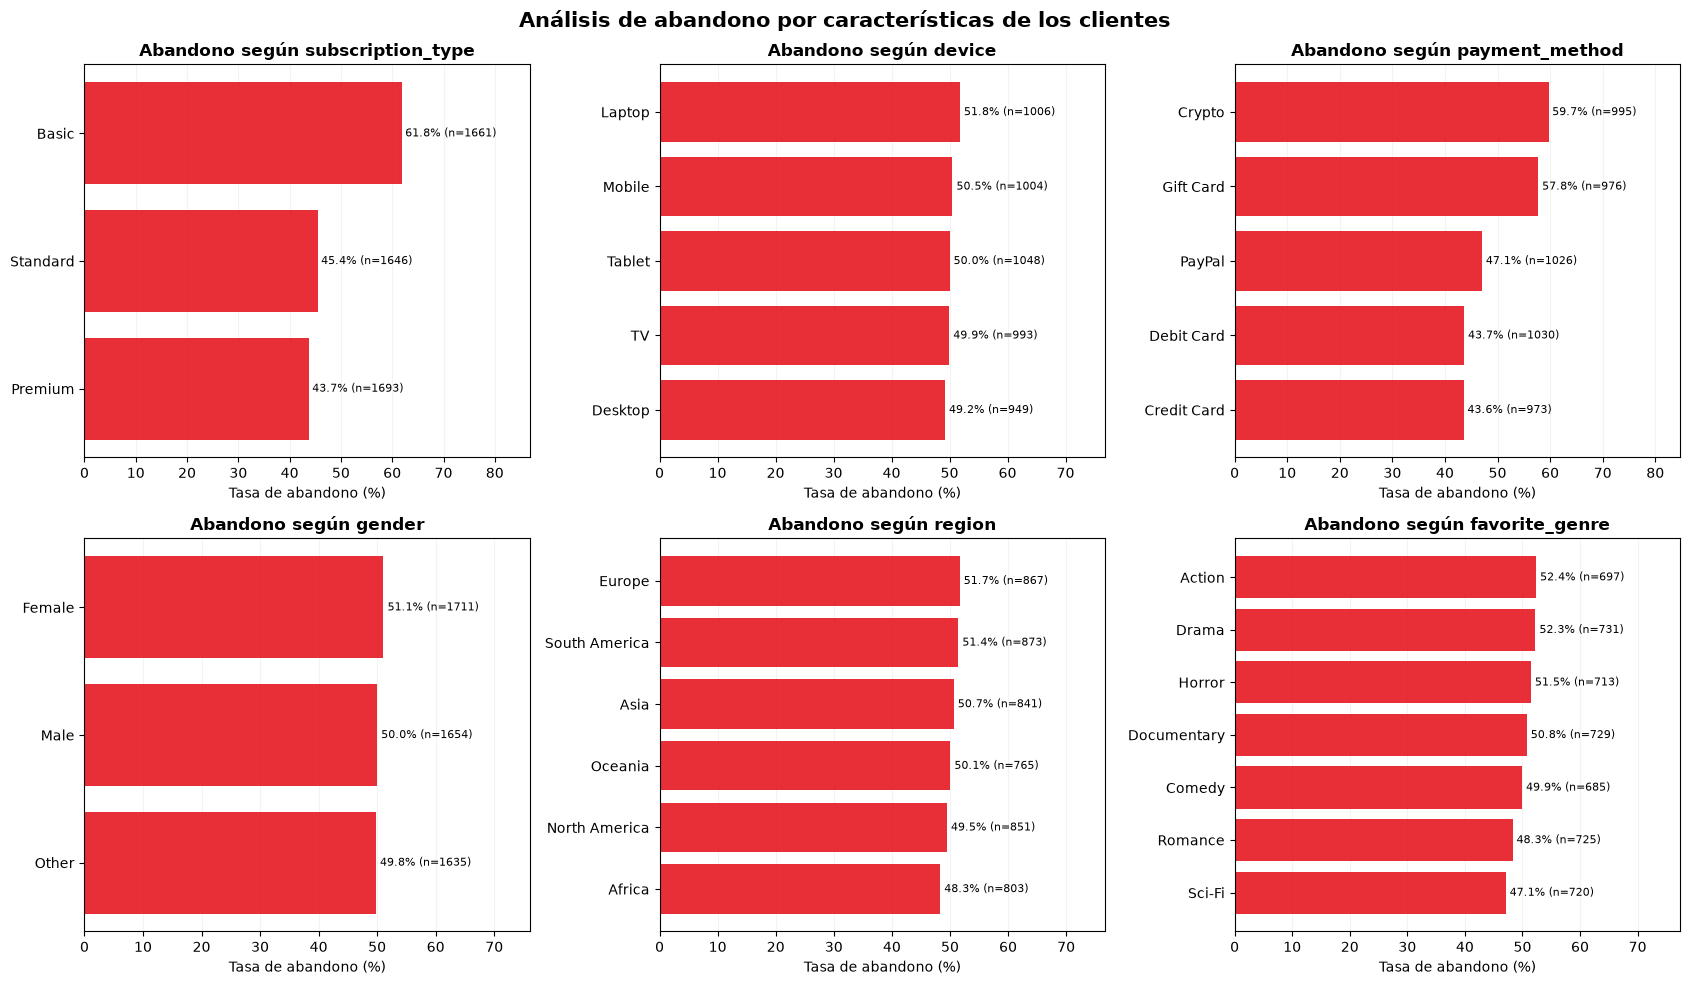

Relación entre suscripción y tarifa mensual:


,Clientes,Tarifas distintas,Tarifa mínima,Tarifa máxima
subscription_type,,,,
Basic,1661,1,8.99,8.99
Premium,1693,1,17.99,17.99
Standard,1646,1,13.99,13.99


In [30]:
categoricas_eda = [
    "subscription_type",
    "device",
    "payment_method",
    "gender",
    "region",
    "favorite_genre"
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, columna in zip(axes.flatten(), categoricas_eda):

    tabla = (
        df.groupby(columna)["churned"]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "Clientes",
            "mean": "Tasa de abandono"
        })
        .sort_values("Tasa de abandono")
    )

    tasas = tabla["Tasa de abandono"] * 100

    barras = ax.barh(
        tabla.index.astype(str),
        tasas,
        color="#E50914",
        alpha=0.85
    )

    for barra, clientes, tasa in zip(
        barras,
        tabla["Clientes"],
        tasas
    ):
        ax.text(
            barra.get_width() + 0.7,
            barra.get_y() + barra.get_height() / 2,
            f"{tasa:.1f}% (n={clientes})",
            va="center",
            fontsize=8
        )

    ax.set_title(
        f"Abandono según {columna}",
        fontweight="bold"
    )

    ax.set_xlabel("Tasa de abandono (%)")
    ax.set_xlim(0, max(65, tasas.max() + 25))
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)

plt.suptitle(
    "Análisis de abandono por características de los clientes",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Tabla complementaria: 
# Revisión del precio mensual según el tipo de suscripción.
# Esto permite investigar si monthly_fee aporta información
# diferente de subscription_type.

print("Relación entre suscripción y tarifa mensual:")

display(
    df.groupby("subscription_type")["monthly_fee"]
    .agg(["count", "nunique", "min", "max"])
    .rename(columns={
        "count": "Clientes",
        "nunique": "Tarifas distintas",
        "min": "Tarifa mínima",
        "max": "Tarifa máxima"
    })
)



Análisis por grupos: watch_hours


,Grupo,Clientes,Tasa_abandono,Mediana_variable
0,"(0.009000000000000001, 2.578]",1000,0.857,1.235
1,"(2.578, 5.94]",1001,0.731,4.090
2,"(5.94, 10.54]",1000,0.440,8.005
3,"(10.54, 18.514]",999,0.405,13.880
4,"(18.514, 110.4]",1000,0.081,26.555



Análisis por grupos: last_login_days


,Grupo,Clientes,Tasa_abandono,Mediana_variable
0,"(-0.001, 12.0]",1072,0.185,6.0
1,"(12.0, 24.0]",943,0.298,19.0
2,"(24.0, 36.0]",989,0.525,30.0
3,"(36.0, 48.0]",1030,0.768,43.0
4,"(48.0, 60.0]",966,0.752,54.0



Análisis por grupos: avg_watch_time_per_day


,Grupo,Clientes,Tasa_abandono,Mediana_variable
0,"(-0.001, 0.09]",1082,0.941,0.04
1,"(0.09, 0.21]",965,0.818,0.15
2,"(0.21, 0.41]",974,0.591,0.30
3,"(0.41, 0.91]",989,0.124,0.60
4,"(0.91, 98.42]",990,0.009,1.81


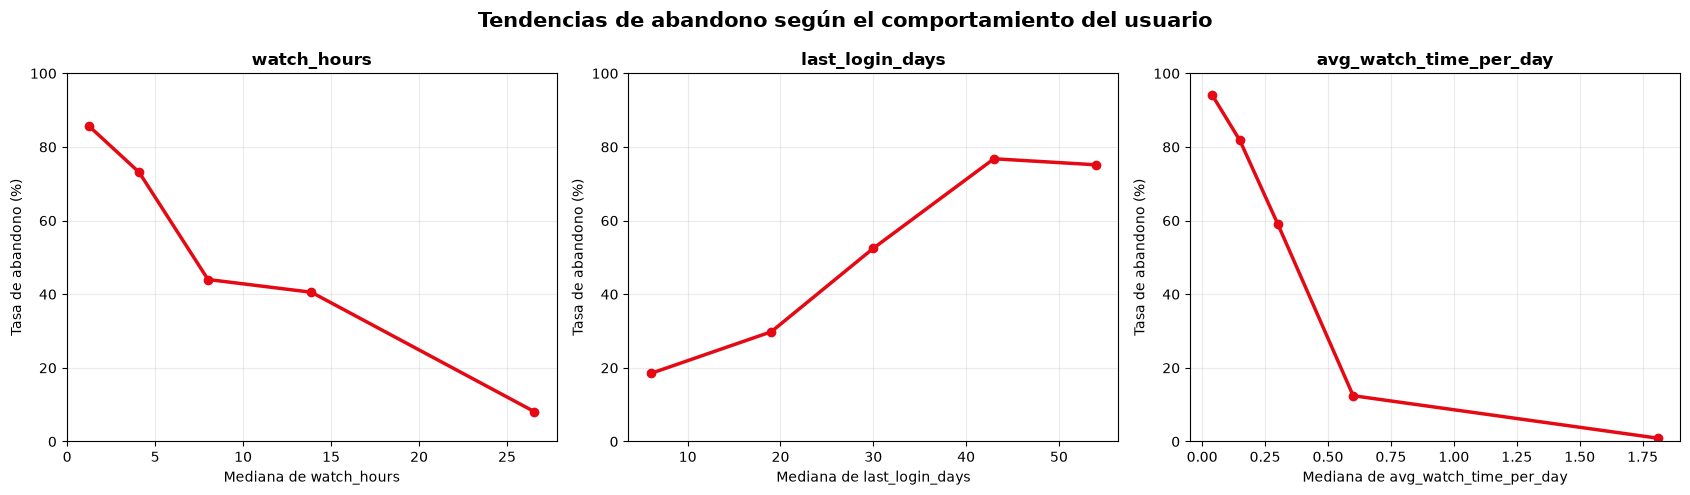

In [31]:
# Dividimos a los clientes en cinco grupos de tamaño
# aproximadamente similar, según su comportamiento.
#
# Esto permite observar si el abandono aumenta o disminuye
# conforme cambian las características del usuario.
#
# Los grupos se utilizan únicamente para el análisis EDA.

variables_comportamiento = [
    "watch_hours",
    "last_login_days",
    "avg_watch_time_per_day"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, columna in zip(axes, variables_comportamiento):

    datos_temporales = df[[columna, "churned"]].copy()

    datos_temporales["Grupo"] = pd.qcut(
        datos_temporales[columna],
        q=5,
        duplicates="drop"
    )

    resumen = (
        datos_temporales.groupby("Grupo", observed=True)
        .agg(
            Clientes=("churned", "size"),
            Tasa_abandono=("churned", "mean"),
            Mediana_variable=(columna, "median")
        )
        .reset_index()
    )

    ax.plot(
        resumen["Mediana_variable"],
        resumen["Tasa_abandono"] * 100,
        marker="o",
        linewidth=2.5,
        color="#E50914"
    )

    ax.set_title(columna, fontweight="bold")
    ax.set_xlabel(f"Mediana de {columna}")
    ax.set_ylabel("Tasa de abandono (%)")
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.25)

    print(f"\nAnálisis por grupos: {columna}")
    display(resumen.round(3))

plt.suptitle(
    "Tendencias de abandono según el comportamiento del usuario",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


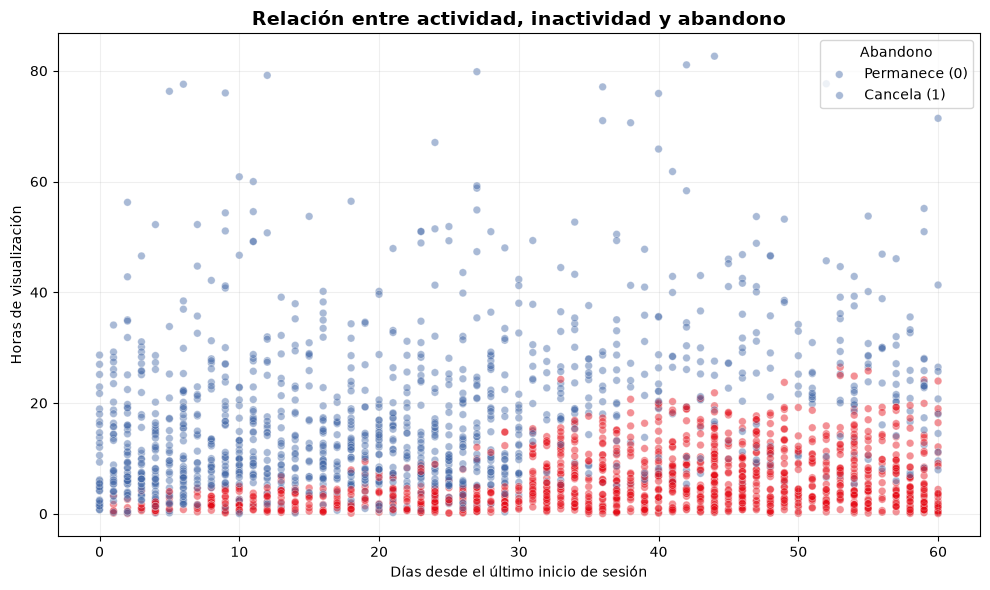

In [32]:
# - Horas de visualización.
# - Días desde el último inicio de sesión.
#
# Comparamos ambas variables para observar si existen
# patrones de separación entre los dos grupos.

# Muestra reproducible utilizada solamente para visualizar
muestra_eda = df.sample(
    n=min(2500, len(df)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=muestra_eda,
    x="last_login_days",
    y="watch_hours",
    hue="churned",
    hue_order=[0, 1],
    palette={
        0: "#4267A6",
        1: "#E50914"
    },
    alpha=0.45,
    s=30
)

plt.title(
    "Relación entre actividad, inactividad y abandono",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Días desde el último inicio de sesión")
plt.ylabel("Horas de visualización")

plt.legend(
    title="Abandono",
    labels=["Permanece (0)", "Cancela (1)"]
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Se utiliza una muestra únicamente para mejorar la
# claridad gráfica. Los 5,000 registros permanecen intactos.


,Pearson,Spearman
avg_watch_time_per_day,-0.273,-0.734
watch_hours,-0.480,-0.541
last_login_days,0.472,0.471
number_of_profiles,-0.159,-0.159
monthly_fee,-0.152,-0.148
age,-0.004,-0.004


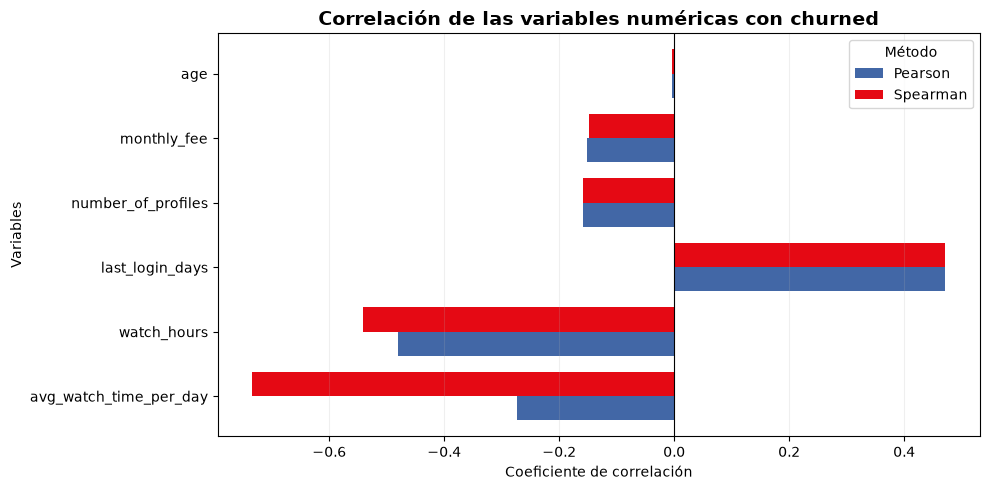

In [33]:
# Complementamos el análisis con Spearman para explorar
# relaciones monotónicas que podrían estar afectadas por
# valores extremos o no ser estrictamente lineales.
#
# Este análisis no determina por sí solo la importancia
# que tendrá cada variable para los clasificadores.

columnas_correlacion = [
    "age",
    "watch_hours",
    "last_login_days",
    "monthly_fee",
    "number_of_profiles",
    "avg_watch_time_per_day",
    "churned"
]

datos_correlacion = df[columnas_correlacion]

correlacion_pearson = (
    datos_correlacion.corr(method="pearson")["churned"]
    .drop("churned")
)

correlacion_spearman = (
    datos_correlacion.corr(method="spearman")["churned"]
    .drop("churned")
)

comparacion_correlaciones = pd.DataFrame({
    "Pearson": correlacion_pearson,
    "Spearman": correlacion_spearman
})

comparacion_correlaciones = (
    comparacion_correlaciones
    .reindex(
        comparacion_correlaciones["Spearman"]
        .abs()
        .sort_values(ascending=False)
        .index
    )
)

display(comparacion_correlaciones.round(3))

# Visualización comparativa
comparacion_correlaciones.plot(
    kind="barh",
    figsize=(10, 5),
    color=["#4267A6", "#E50914"],
    width=0.75
)

plt.title(
    "Correlación de las variables numéricas con churned",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Coeficiente de correlación")
plt.ylabel("Variables")
plt.axvline(0, color="black", linewidth=0.8)
plt.grid(axis="x", alpha=0.2)
plt.legend(title="Método")

plt.tight_layout()
plt.show()

# Interpretación:
# Valores positivos: asociación con mayor abandono.
# Valores negativos: asociación con menor abandono.
# Valores cercanos a cero: asociación débil según el método.
#
# La correlación no implica causalidad.


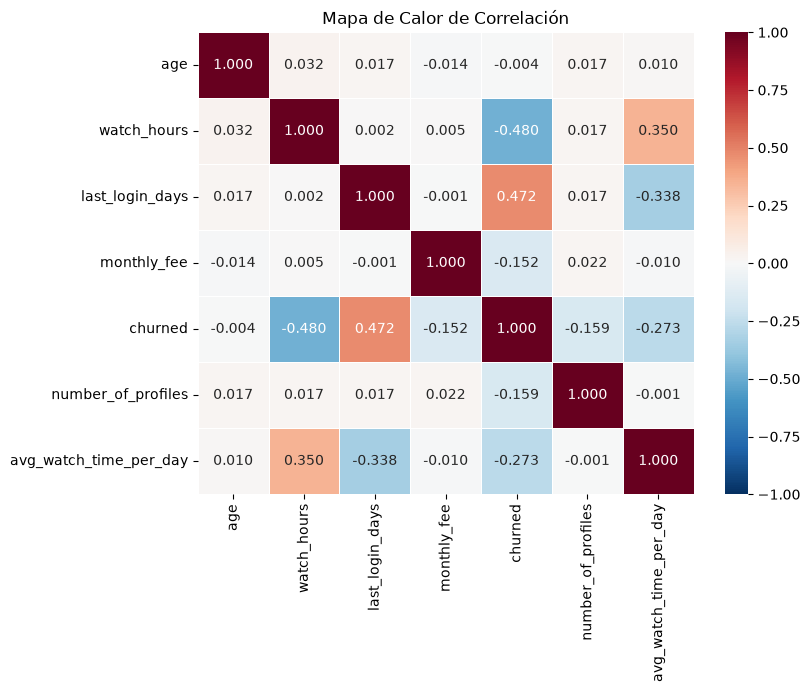

In [34]:
matriz_corr = df.select_dtypes(include=['float64', 'int64']).corr()
# O simplemente: matriz_corr = df.corr(numeric_only=True)

# 3. Configurar el tamaño de la figura
plt.figure(figsize=(8, 6))

# 4. Generar el mapa de calor
sns.heatmap(
    matriz_corr,
    annot=True,  # Muestra los valores numéricos en cada celda
    fmt='.3f',  # Formato de dos decimales
    cmap='RdBu_r',  # Paleta de colores
    linewidths=0.5,  # Líneas divisorias entre celdas
    vmin=-1,
    vmax=1,
)

# 5. Mostrar el gráfico
plt.title('Mapa de Calor de Correlación')
plt.show()

In [35]:
# Esta celda reúne los principales hallazgos descriptivos
# antes de comenzar la preparación de variables para modelos.

total = len(df)
cancelaciones = int((df["churned"] == 1).sum())
permanencias = int((df["churned"] == 0).sum())

print("=" * 60)
print("RESUMEN DEL ANÁLISIS EXPLORATORIO - NETFLIX")
print("=" * 60)

print(f"\nTotal de clientes: {total:,}")
print(f"Total de variables originales: {df.shape[1]}")
print(f"Clientes que permanecen: {permanencias:,}")
print(f"Clientes que abandonaron: {cancelaciones:,}")

print(f"\nTasa general de abandono: {cancelaciones / total:.2%}")

print("\nCalidad de los datos:")
print(f"Valores nulos: {df.isna().sum().sum():,}")
print(f"Registros duplicados: {df.duplicated().sum():,}")

print("\nComparación de comportamiento según abandono:")

resumen_comportamiento = (
    df.groupby("churned")[
        [
            "watch_hours",
            "last_login_days",
            "avg_watch_time_per_day"
        ]
    ]
    .median()
    .rename(index={
        0: "Permanece",
        1: "Cancela"
    })
)

display(resumen_comportamiento.round(2))

print("\nVariables con mayor correlación absoluta con churn:")

display(
    comparacion_correlaciones
    .assign(
        Magnitud_Spearman=lambda x: x["Spearman"].abs()
    )
    .sort_values("Magnitud_Spearman", ascending=False)
    .head(5)
    .drop(columns="Magnitud_Spearman")
    .round(3)
)

print("\nConclusión metodológica:")
print(
    "El EDA permite identificar patrones descriptivos "
    "relacionados con el abandono de clientes."
)
print(
    "Se revisaron la calidad, los valores atípicos, "
    "las distribuciones y las asociaciones entre variables."
)
print(
    "Los resultados permiten evaluar preliminarmente "
    "la hipótesis de que la actividad y la inactividad "
    "se relacionan con el abandono de la plataforma."
)
print(
    "Las asociaciones observadas no demuestran causalidad "
    "ni garantizan capacidad predictiva."
)
print(
    "No se modificaron los registros originales ni "
    "las características seleccionadas para los modelos."
)

print("=" * 60)
print("FIN DEL EDA - SIGUIENTE ETAPA: ENCODING")
print("=" * 60)

RESUMEN DEL ANÁLISIS EXPLORATORIO - NETFLIX

Total de clientes: 5,000
Total de variables originales: 14
Clientes que permanecen: 2,485
Clientes que abandonaron: 2,515

Tasa general de abandono: 50.30%

Calidad de los datos:
Valores nulos: 0
Registros duplicados: 0

Comparación de comportamiento según abandono:


,watch_hours,last_login_days,avg_watch_time_per_day
churned,,,
Permanece,13.86,19.0,0.72
Cancela,4.06,41.0,0.12



Variables con mayor correlación absoluta con churn:


,Pearson,Spearman
avg_watch_time_per_day,-0.273,-0.734
watch_hours,-0.480,-0.541
last_login_days,0.472,0.471
number_of_profiles,-0.159,-0.159
monthly_fee,-0.152,-0.148



Conclusión metodológica:
El EDA permite identificar patrones descriptivos relacionados con el abandono de clientes.
Se revisaron la calidad, los valores atípicos, las distribuciones y las asociaciones entre variables.
Los resultados permiten evaluar preliminarmente la hipótesis de que la actividad y la inactividad se relacionan con el abandono de la plataforma.
Las asociaciones observadas no demuestran causalidad ni garantizan capacidad predictiva.
No se modificaron los registros originales ni las características seleccionadas para los modelos.
FIN DEL EDA - SIGUIENTE ETAPA: ENCODING


In [36]:
# Variable objetivo
target = "churned"

# Variables numéricas
variables_numericas = [
    "age",
    "watch_hours",
    "last_login_days",
    "monthly_fee",
    "number_of_profiles",
    "avg_watch_time_per_day"
]

# Variables categóricas
variables_categoricas = [
    "gender",
    "subscription_type",
    "region",
    "device",
    "payment_method",
    "favorite_genre"
]

# Incorporamos todas las características disponibles,
# excepto customer_id y la variable objetivo.
variables = variables_numericas + variables_categoricas

# Creamos una copia para modelado.
# El dataset original permanece intacto.
df_modelo = df[variables + [target]].copy()

print("Dimensiones originales:", df.shape)
print("Dimensiones antes de codificación:", df_modelo.shape)

print("\nVariables numéricas:")
print(variables_numericas)

print("\nVariables categóricas:")
print(variables_categoricas)

print("\nVariable objetivo:", target)
print("Variable eliminada: customer_id")

display(df_modelo.head())


Dimensiones originales: (5000, 14)
Dimensiones antes de codificación: (5000, 13)

Variables numéricas:
['age', 'watch_hours', 'last_login_days', 'monthly_fee', 'number_of_profiles', 'avg_watch_time_per_day']

Variables categóricas:
['gender', 'subscription_type', 'region', 'device', 'payment_method', 'favorite_genre']

Variable objetivo: churned
Variable eliminada: customer_id


,age,watch_hours,last_login_days,monthly_fee,number_of_profiles,avg_watch_time_per_day,gender,subscription_type,region,device,payment_method,favorite_genre,churned
0,51,14.73,29,8.99,1,0.49,Other,Basic,Africa,TV,Gift Card,Action,1
1,47,0.70,19,13.99,5,0.03,Other,Standard,Europe,Mobile,Gift Card,Sci-Fi,1
2,27,16.32,10,13.99,2,1.48,Female,Standard,Asia,TV,Crypto,Drama,0
3,53,4.51,12,17.99,2,0.35,Other,Premium,Oceania,TV,Crypto,Horror,1
4,56,1.89,13,13.99,2,0.13,Other,Standard,Africa,Mobile,Crypto,Action,1


In [37]:
print("VALIDACIÓN DEL DATASET")
print("=" * 50)

# Valores nulos y registros duplicados
print("Valores nulos:", df_modelo.isnull().sum().sum())
print("Registros duplicados:", df_modelo.duplicated().sum())

# Verificar tipos numéricos
for columna in variables_numericas:
    if not pd.api.types.is_numeric_dtype(df_modelo[columna]):
        raise TypeError(
            f"La variable {columna} no tiene tipo numérico."
        )

# Verificar que la variable objetivo sea binaria
assert df_modelo[target].isin([0, 1]).all(), \
    "La variable objetivo contiene valores diferentes de 0 y 1."

# No realizar codificación si existen nulos
assert not df_modelo.isnull().any().any(), \
    "Existen valores nulos pendientes de tratamiento."

# Revisar las categorías originales
for columna in variables_categoricas:
    print(f"\nVariable: {columna}")
    print("Categorías:", df_modelo[columna].nunique())
    print(df_modelo[columna].value_counts())

# Resumen de las variables categóricas
resumen_categorias = pd.DataFrame({
    "Variable": variables_categoricas,
    "Número de categorías": [
        df_modelo[col].nunique()
        for col in variables_categoricas
    ]
})

print("\nRESUMEN DE CATEGORÍAS")
display(resumen_categorias)

print("\nValidación previa completada.")


VALIDACIÓN DEL DATASET
Valores nulos: 0
Registros duplicados: 0

Variable: gender
Categorías: 3
gender
Female    1711
Male      1654
Other     1635
Name: count, dtype: int64

Variable: subscription_type
Categorías: 3
subscription_type
Premium     1693
Basic       1661
Standard    1646
Name: count, dtype: int64

Variable: region
Categorías: 6
region
South America    873
Europe           867
North America    851
Asia             841
Africa           803
Oceania          765
Name: count, dtype: int64

Variable: device
Categorías: 5
device
Tablet     1048
Laptop     1006
Mobile     1004
TV          993
Desktop     949
Name: count, dtype: int64

Variable: payment_method
Categorías: 5
payment_method
Debit Card     1030
PayPal         1026
Crypto          995
Gift Card       976
Credit Card     973
Name: count, dtype: int64

Variable: favorite_genre
Categorías: 7
favorite_genre
Drama          731
Documentary    729
Romance        725
Sci-Fi         720
Horror         713
Action         697
Co

,Variable,Número de categorías
0,gender,3
1,subscription_type,3
2,region,6
3,device,5
4,payment_method,5
5,favorite_genre,7



Validación previa completada.


In [38]:
df_encoded = pd.get_dummies(
    df_modelo,
    columns=variables_categoricas,
    drop_first=False,
    dtype=int
)

print("Dimensiones antes:", df_modelo.shape)
print("Dimensiones después:", df_encoded.shape)

print("\nColumnas generadas:")
display(pd.DataFrame({
    "Variable": df_encoded.columns
}))

print("\nPrimeras filas del dataset codificado:")
display(df_encoded.head())

# Validaciones posteriores
assert df_encoded.select_dtypes(
    include=["object", "category", "str"]
).empty, "Todavía existen columnas categóricas."

assert df_encoded["churned"].equals(df_modelo["churned"]), \
    "La variable objetivo fue modificada."

assert "customer_id" not in df_encoded.columns, \
    "El identificador no debe utilizarse como predictor."

for columna in variables_categoricas:

    columnas_generadas = [
        col for col in df_encoded.columns
        if col.startswith(f"{columna}_")
    ]

    # Cada cliente debe pertenecer a una categoría
    assert (df_encoded[columnas_generadas].sum(axis=1) == 1).all(), \
        f"Error en la codificación de {columna}"

print("\nOne-Hot Encoding completado correctamente.")


Dimensiones antes: (5000, 13)
Dimensiones después: (5000, 36)

Columnas generadas:


,Variable
0,age
1,watch_hours
2,last_login_days
3,monthly_fee
4,number_of_profiles
5,avg_watch_time_per_day
6,churned
7,gender_Female
8,gender_Male
9,gender_Other



Primeras filas del dataset codificado:


,age,watch_hours,last_login_days,monthly_fee,number_of_profiles,avg_watch_time_per_day,churned,gender_Female,gender_Male,gender_Other,...,payment_method_Debit Card,payment_method_Gift Card,payment_method_PayPal,favorite_genre_Action,favorite_genre_Comedy,favorite_genre_Documentary,favorite_genre_Drama,favorite_genre_Horror,favorite_genre_Romance,favorite_genre_Sci-Fi
0,51,14.73,29,8.99,1,0.49,1,0,0,1,...,0,1,0,1,0,0,0,0,0,0
1,47,0.70,19,13.99,5,0.03,1,0,0,1,...,0,1,0,0,0,0,0,0,0,1
2,27,16.32,10,13.99,2,1.48,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0
3,53,4.51,12,17.99,2,0.35,1,0,0,1,...,0,0,0,0,0,0,0,1,0,0
4,56,1.89,13,13.99,2,0.13,1,0,0,1,...,0,0,0,1,0,0,0,0,0,0



One-Hot Encoding completado correctamente.


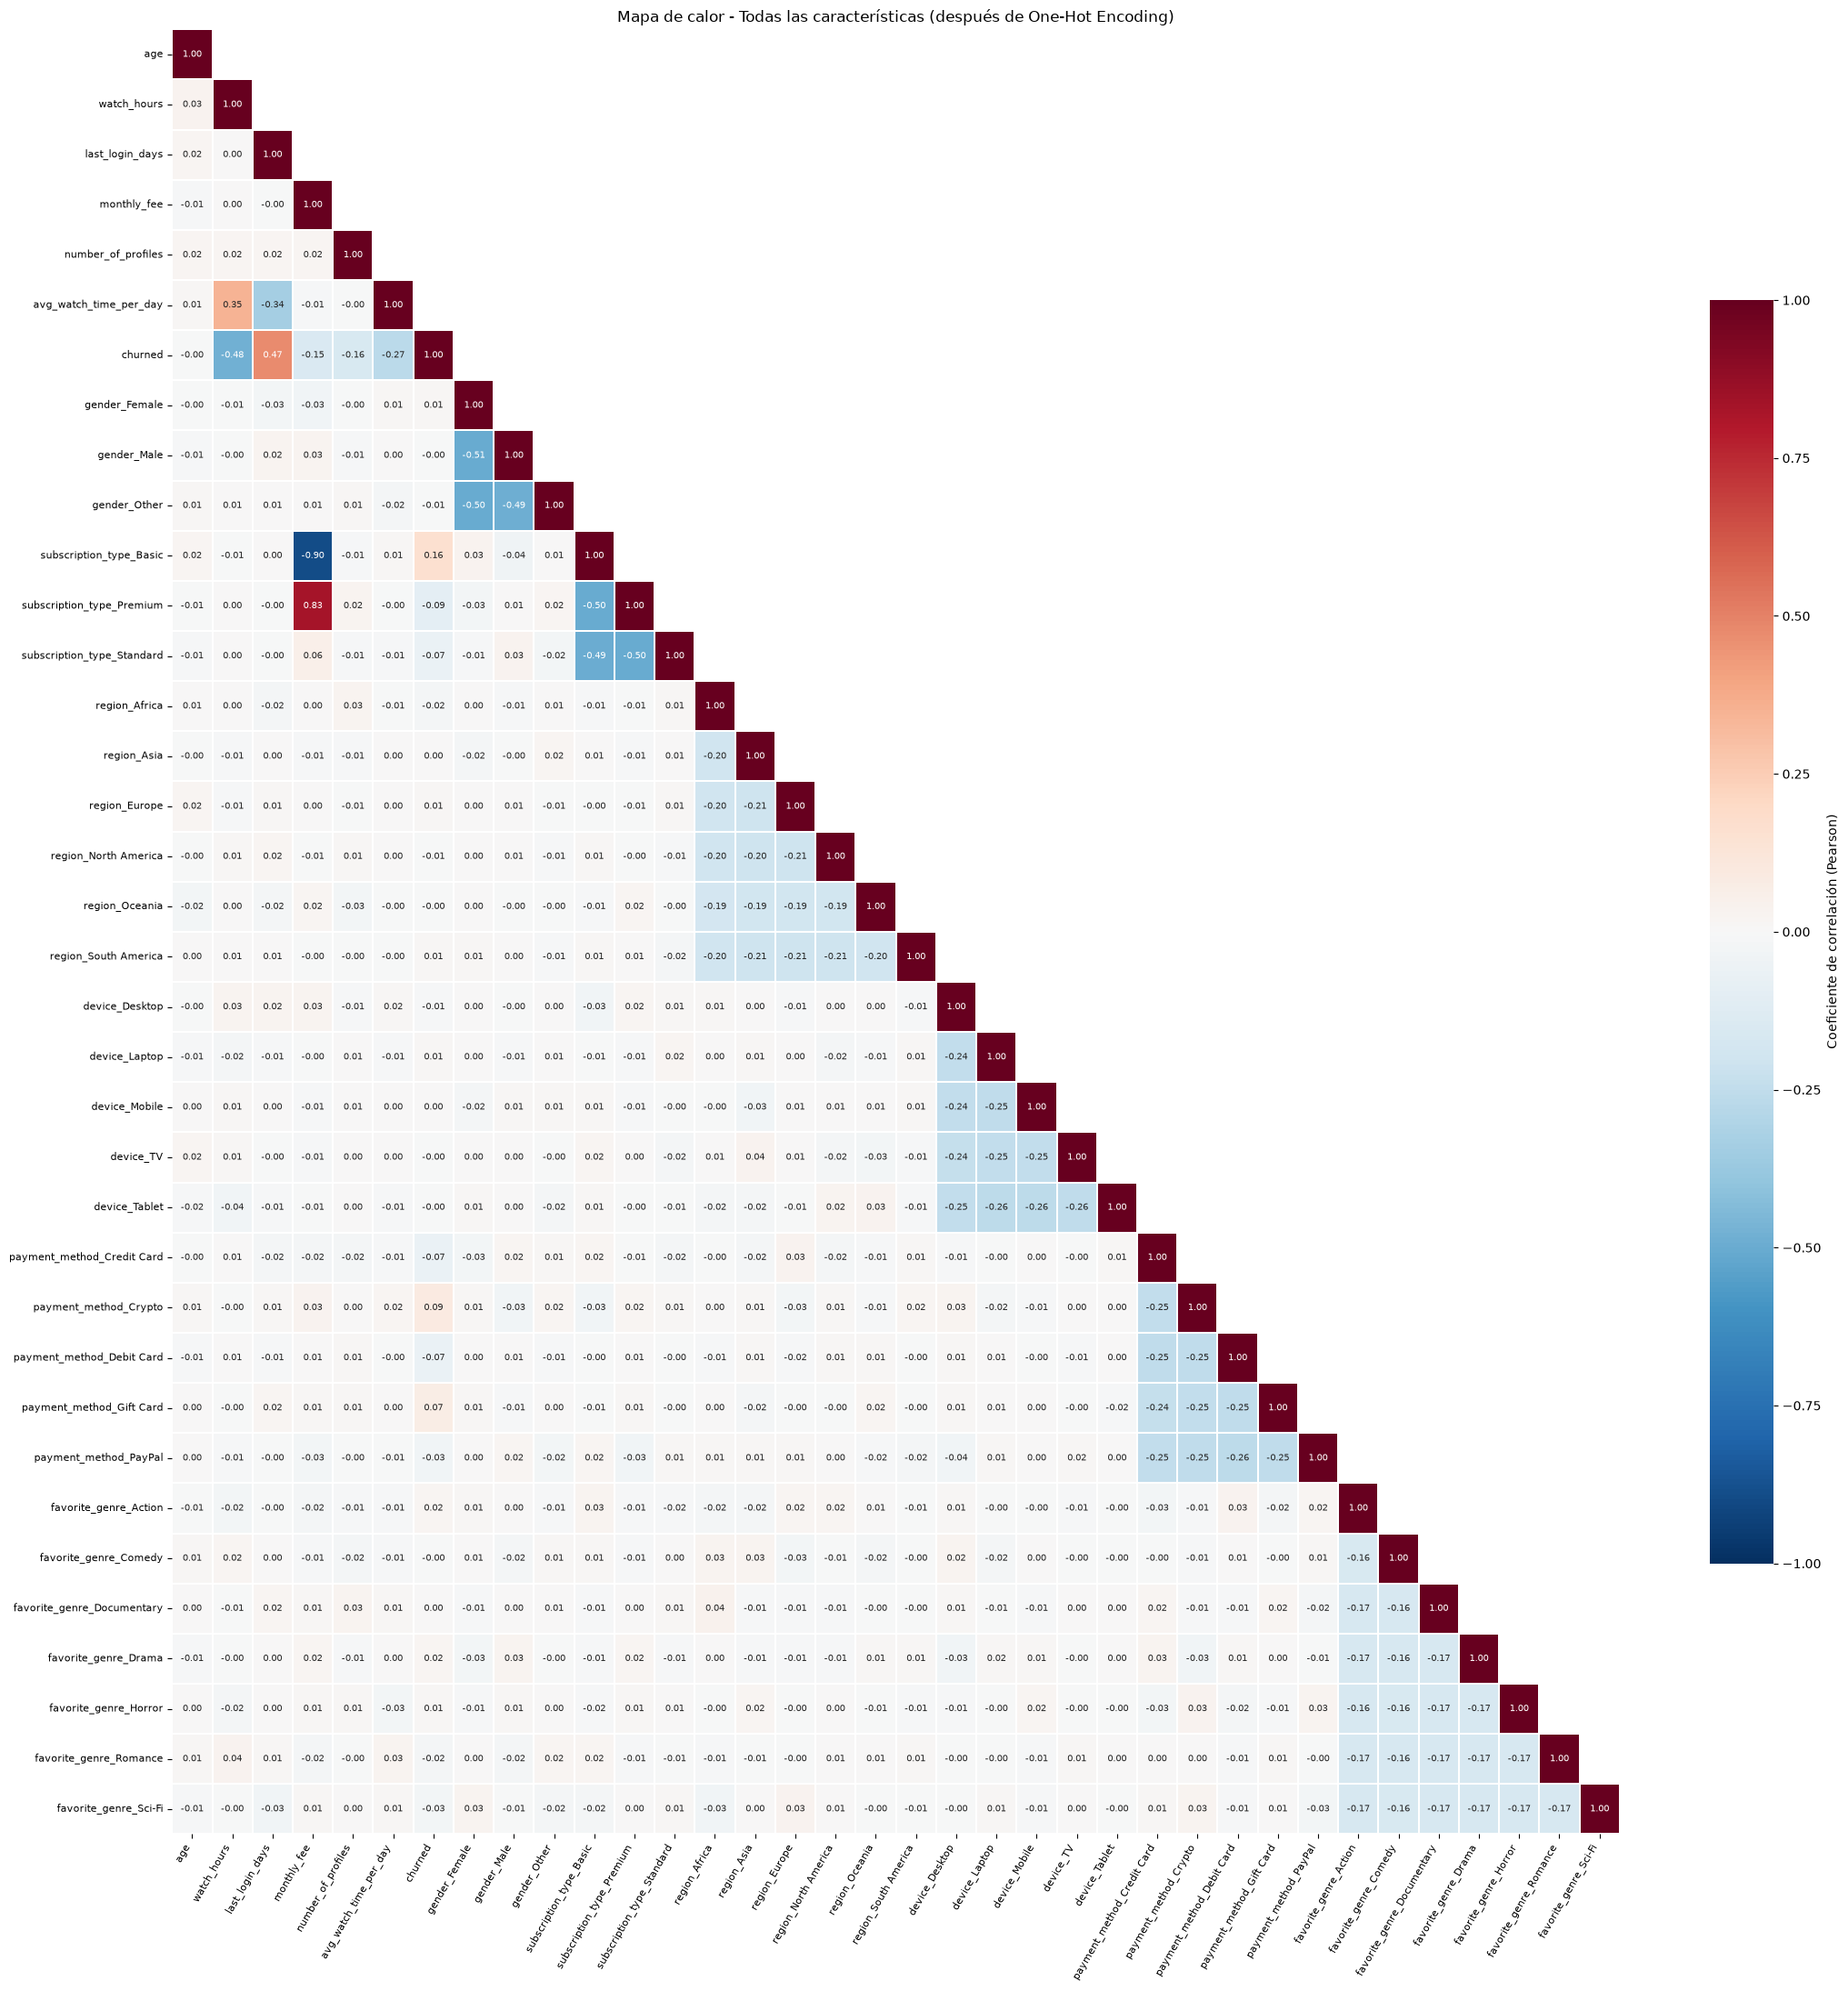

In [39]:
# Correlación de todas las columnas del dataset codificado
corr_total = df_encoded.corr()
mascara_total = np.triu(np.ones_like(corr_total, dtype=bool), k=1)

plt.figure(figsize=(22, 22))
sns.heatmap(
    corr_total,
    mask=mascara_total,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    cmap="RdBu_r",
    vmin=-1, vmax=1, center=0,
    linewidths=0.3,
    cbar_kws={"shrink": 0.7, "label": "Coeficiente de correlación (Pearson)"}
)
plt.title("Mapa de calor - Todas las características (después de One-Hot Encoding)")
plt.xticks(rotation=60, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

In [40]:

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Cuatro características numéricas seleccionadas
numericas_base = [
    "watch_hours",
    "last_login_days",
    "avg_watch_time_per_day",
    "number_of_profiles"
]

# Recuperamos las columnas generadas por One-Hot Encoding
columnas_suscripcion = sorted([
    col for col in df_encoded.columns
    if col.startswith("subscription_type_")
])

# Comprobamos que existan las columnas necesarias
faltantes = [
    col for col in numericas_base + ["churned"]
    if col not in df_encoded.columns
]

if faltantes or not columnas_suscripcion:
    raise ValueError(
        f"Revisa el One-Hot Encoding. "
        f"Columnas faltantes: {faltantes}"
    )

# Características y variable objetivo
columnas_base = numericas_base + columnas_suscripcion

X_churn = df_encoded[columnas_base].copy()
y_churn = df_encoded["churned"].astype(int).copy()

# Validación
assert not X_churn.isna().any().any()
assert set(y_churn.unique()) == {0, 1}
assert np.isfinite(X_churn.to_numpy(dtype=float)).all()

print("Características seleccionadas:")
print(X_churn.columns.tolist())

print("\nDimensiones de X:", X_churn.shape)
print("Dimensiones de y:", y_churn.shape)

print("\nDistribución de churned:")
print(y_churn.value_counts())

display(X_churn.head())


Características seleccionadas:
['watch_hours', 'last_login_days', 'avg_watch_time_per_day', 'number_of_profiles', 'subscription_type_Basic', 'subscription_type_Premium', 'subscription_type_Standard']

Dimensiones de X: (5000, 7)
Dimensiones de y: (5000,)

Distribución de churned:
churned
1    2515
0    2485
Name: count, dtype: int64


,watch_hours,last_login_days,avg_watch_time_per_day,number_of_profiles,subscription_type_Basic,subscription_type_Premium,subscription_type_Standard
0,14.73,29,0.49,1,1,0,0
1,0.70,19,0.03,5,0,0,1
2,16.32,10,1.48,2,0,0,1
3,4.51,12,0.35,2,0,1,0
4,1.89,13,0.13,2,0,0,1


In [41]:
X_train_churn, X_test_churn, y_train_churn, y_test_churn = (
    train_test_split(
        X_churn,
        y_churn,
        test_size=0.20,
        random_state=42,
        stratify=y_churn
    )
)

print("Entrenamiento:", X_train_churn.shape)
print("Prueba:", X_test_churn.shape)

print("\nDistribución en entrenamiento:")
print(y_train_churn.value_counts(normalize=True).round(3))

print("\nDistribución en prueba:")
print(y_test_churn.value_counts(normalize=True).round(3))


Entrenamiento: (4000, 7)
Prueba: (1000, 7)

Distribución en entrenamiento:
churned
1    0.503
0    0.497
Name: proportion, dtype: float64

Distribución en prueba:
churned
1    0.503
0    0.497
Name: proportion, dtype: float64


In [42]:
%pip install xgboost

from xgboost import XGBClassifier

def construir_modelos(columnas):

    # Estandarizamos exclusivamente las variables numéricas
    # para Regresión Logística.
    # El escalador se ajusta dentro de cada entrenamiento
    # y de cada partición de validación cruzada.

    numericas = [
        col for col in numericas_base
        if col in columnas
    ]

    preprocesador_logistico = ColumnTransformer(
        transformers=[
            ("escalado", StandardScaler(), numericas)
        ],
        remainder="passthrough"
    )

    modelos = {

        # MODELO 1: REGRESIÓN LOGÍSTICA
        "Regresión Logística": Pipeline([
            ("preprocesamiento", preprocesador_logistico),
            ("clasificador", LogisticRegression(
                max_iter=2000,
                random_state=42
            ))
        ]),

        # MODELO 2: ÁRBOL DE DECISIÓN
        "Árbol de Decisión": DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=10,
            random_state=42
        ),

        # MODELO 3: RANDOM FOREST
        "Random Forest": RandomForestClassifier(
            n_estimators=150,
            max_depth=9,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ),

        # MODELO 4: GRADIENT BOOSTING
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=120,
            learning_rate=0.06,
            max_depth=3,
            random_state=42
        ),

        # MODELO 5: XGBOOST
        "XGBoost": XGBClassifier(
            objective="binary:logistic",
            n_estimators=150,
            learning_rate=0.05,
            max_depth=4,
            min_child_weight=3,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=2
        )
    }

    return modelos


print("=" * 55)
print("MODELOS DE CLASIFICACIÓN - NETFLIX CHURN")
print("=" * 55)

for i, nombre in enumerate(
    construir_modelos(columnas_base).keys(), start=1
):
    print(f"{i}. {nombre}")

print("\nTotal de clasificadores:", len(construir_modelos(columnas_base)))



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
MODELOS DE CLASIFICACIÓN - NETFLIX CHURN
1. Regresión Logística
2. Árbol de Decisión
3. Random Forest
4. Gradient Boosting
5. XGBoost

Total de clasificadores: 5


COMPARACIÓN MEDIANTE VALIDACIÓN CRUZADA


,Escenario,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,Desviación F1
0,Todas las seleccionadas,XGBoost,0.9420,0.9668,0.9165,0.9408,0.9910,0.0075
1,Todas las seleccionadas,Gradient Boosting,0.9400,0.9579,0.9215,0.9392,0.9912,0.0074
2,Todas las seleccionadas,Random Forest,0.9362,0.9575,0.9140,0.9352,0.9898,0.0087
3,Todas las seleccionadas,Árbol de Decisión,0.9362,0.9641,0.9071,0.9347,0.9852,0.0128
4,Sin avg_watch_time_per_day,XGBoost,0.9342,0.9577,0.9095,0.9329,0.9886,0.0103
5,Sin avg_watch_time_per_day,Gradient Boosting,0.9333,0.9509,0.9150,0.9323,0.9888,0.0124
6,Sin avg_watch_time_per_day,Random Forest,0.9325,0.9533,0.9105,0.9313,0.9884,0.0102
7,Sin avg_watch_time_per_day,Árbol de Decisión,0.9315,0.9667,0.8946,0.9293,0.9834,0.0145
8,Sin last_login_days,Gradient Boosting,0.9235,0.9138,0.9364,0.9249,0.9847,0.0075
9,Sin last_login_days,XGBoost,0.9238,0.9179,0.9319,0.9248,0.9852,0.0085



MEJOR CONFIGURACIÓN
Modelo: XGBoost
Escenario: Todas las seleccionadas
F1 promedio: 0.9408
Recall promedio: 0.9165


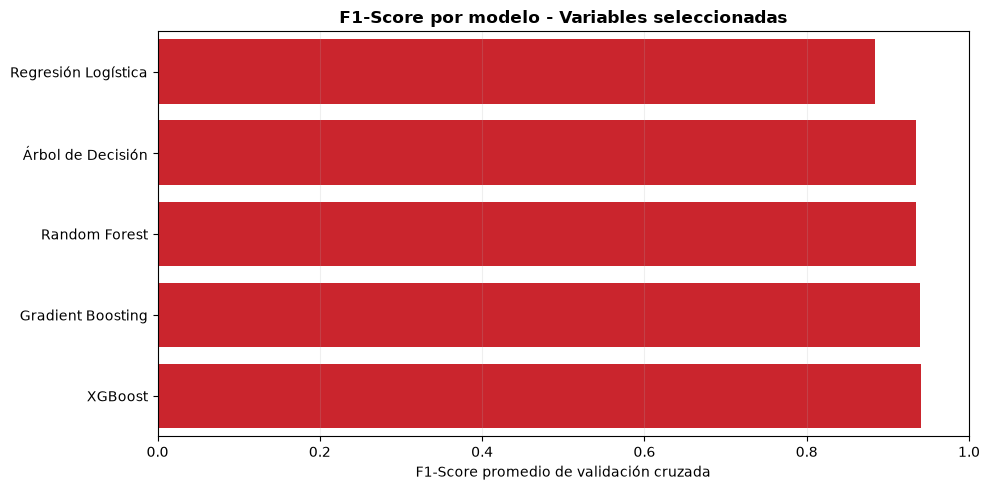

In [43]:
escenarios = {
    "Todas las seleccionadas": columnas_base,

    "Sin last_login_days": [
        col for col in columnas_base
        if col != "last_login_days"
    ],

    "Sin avg_watch_time_per_day": [
        col for col in columnas_base
        if col != "avg_watch_time_per_day"
    ],

    "Sin ambas en revisión": [
        col for col in columnas_base
        if col not in {
            "last_login_days",
            "avg_watch_time_per_day"
        }
    ]
}

# Cinco particiones de validación cruzada
cv_churn = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Métricas
metricas_cv = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC-AUC": "roc_auc"
}

filas_cv = []

for escenario, columnas in escenarios.items():

    for nombre, modelo in construir_modelos(columnas).items():

        puntuaciones = cross_validate(
            modelo,
            X_train_churn[columnas],
            y_train_churn,
            cv=cv_churn,
            scoring=metricas_cv,
            n_jobs=1,
            error_score="raise"
        )

        fila = {
            "Escenario": escenario,
            "Modelo": nombre
        }

        for metrica in metricas_cv:
            fila[metrica] = puntuaciones[
                f"test_{metrica}"
            ].mean()

        fila["Desviación F1"] = puntuaciones[
            "test_F1"
        ].std()

        filas_cv.append(fila)

# Tabla de resultados
resultados_cv = pd.DataFrame(filas_cv)

resultados_cv = resultados_cv.sort_values(
    by=["F1", "Recall", "ROC-AUC"],
    ascending=False
).reset_index(drop=True)

print("COMPARACIÓN MEDIANTE VALIDACIÓN CRUZADA")

display(resultados_cv.round(4))

# Mejor combinación según F1 de validación cruzada
mejor_escenario = resultados_cv.loc[0, "Escenario"]
mejor_nombre = resultados_cv.loc[0, "Modelo"]

print("\nMEJOR CONFIGURACIÓN")
print("Modelo:", mejor_nombre)
print("Escenario:", mejor_escenario)
print("F1 promedio:", round(resultados_cv.loc[0, "F1"], 4))
print("Recall promedio:", round(resultados_cv.loc[0, "Recall"], 4))

# Gráfico comparativo: F1 de los cuatro modelos
# usando todas las variables seleccionadas.
comparacion_inicial = resultados_cv[
    resultados_cv["Escenario"] == "Todas las seleccionadas"
].sort_values("F1")

plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparacion_inicial,
    x="F1",
    y="Modelo",
    color="#E50914"
)

plt.title(
    "F1-Score por modelo - Variables seleccionadas",
    fontweight="bold"
)
plt.xlabel("F1-Score promedio de validación cruzada")
plt.ylabel("")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


In [44]:
columnas_finales = escenarios[mejor_escenario]

modelos_finales = construir_modelos(columnas_finales)

filas_test = []
predicciones_test = {}
probabilidades_test = {}

for nombre, modelo in modelos_finales.items():

    # Entrenar únicamente con datos de entrenamiento
    modelo.fit(
        X_train_churn[columnas_finales],
        y_train_churn
    )

    # Predicción en registros nunca vistos
    pred = modelo.predict(
        X_test_churn[columnas_finales]
    )

    prob = modelo.predict_proba(
        X_test_churn[columnas_finales]
    )[:, 1]

    predicciones_test[nombre] = pred
    probabilidades_test[nombre] = prob

    filas_test.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test_churn, pred),
        "Precision": precision_score(
            y_test_churn, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test_churn, pred, zero_division=0
        ),
        "F1": f1_score(
            y_test_churn, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test_churn, prob)
    })

resultados_test = pd.DataFrame(filas_test).sort_values(
    "F1", ascending=False
)

print("RESULTADOS EN PRUEBA")
print("Escenario evaluado:", mejor_escenario)

display(resultados_test.round(4))

# Conservamos el ganador elegido con validación cruzada
modelo_ganador = modelos_finales[mejor_nombre]

print("\nMODELO SELECCIONADO:", mejor_nombre)

print("\nREPORTE DE CLASIFICACIÓN")
print(
    classification_report(
        y_test_churn,
        predicciones_test[mejor_nombre],
        labels=[0, 1],
        target_names=["Permanece (0)", "Abandona (1)"],
        zero_division=0
    )
)

# Verificación de hipótesis: clase churned = 1
f1_final = f1_score(
    y_test_churn,
    predicciones_test[mejor_nombre]
)

recall_final = recall_score(
    y_test_churn,
    predicciones_test[mejor_nombre]
)

print("\nEVALUACIÓN DE LA HIPÓTESIS")

if f1_final >= 0.90 and recall_final >= 0.90:
    print("Hipótesis cumplida en el conjunto de prueba.")
else:
    print("Hipótesis no cumplida en el conjunto de prueba.")

print(f"F1-Score: {f1_final:.4f}")
print(f"Recall: {recall_final:.4f}")

# Ejemplo de predicciones individuales
ejemplos = X_test_churn[columnas_finales].copy()

ejemplos["Churn_real"] = y_test_churn
ejemplos["Prediccion"] = predicciones_test[mejor_nombre]
ejemplos["Probabilidad_abandono"] = (
    probabilidades_test[mejor_nombre]
)

print("\nEJEMPLOS DE PREDICCIÓN")
display(ejemplos.head(10).round(3))


RESULTADOS EN PRUEBA
Escenario evaluado: Todas las seleccionadas


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
2,Random Forest,0.936,0.9545,0.9165,0.9351,0.9898
4,XGBoost,0.934,0.9543,0.9125,0.9329,0.9907
1,Árbol de Decisión,0.935,0.9720,0.8966,0.9328,0.9843
3,Gradient Boosting,0.930,0.9391,0.9205,0.9297,0.9903
0,Regresión Logística,0.884,0.8700,0.9046,0.8869,0.9583



MODELO SELECCIONADO: XGBoost

REPORTE DE CLASIFICACIÓN
               precision    recall  f1-score   support

Permanece (0)       0.92      0.96      0.94       497
 Abandona (1)       0.95      0.91      0.93       503

     accuracy                           0.93      1000
    macro avg       0.93      0.93      0.93      1000
 weighted avg       0.93      0.93      0.93      1000


EVALUACIÓN DE LA HIPÓTESIS
Hipótesis cumplida en el conjunto de prueba.
F1-Score: 0.9329
Recall: 0.9125

EJEMPLOS DE PREDICCIÓN


,watch_hours,last_login_days,avg_watch_time_per_day,number_of_profiles,subscription_type_Basic,subscription_type_Premium,subscription_type_Standard,Churn_real,Prediccion,Probabilidad_abandono
1911,26.05,21,1.18,4,0,0,1,0,0,0.001
3551,2.34,54,0.04,4,0,1,0,1,1,0.980
1241,6.06,30,0.20,4,1,0,0,0,0,0.228
3182,9.44,46,0.20,2,1,0,0,1,1,0.997
3678,0.10,20,0.00,1,0,1,0,1,1,0.980
1873,1.59,29,0.05,3,1,0,0,1,1,0.997
2831,6.23,49,0.12,3,0,0,1,1,1,0.985
1362,2.46,53,0.05,1,1,0,0,1,1,1.000
1385,4.33,25,0.17,4,0,0,1,0,1,0.521
2016,9.54,60,0.16,5,0,0,1,0,0,0.461


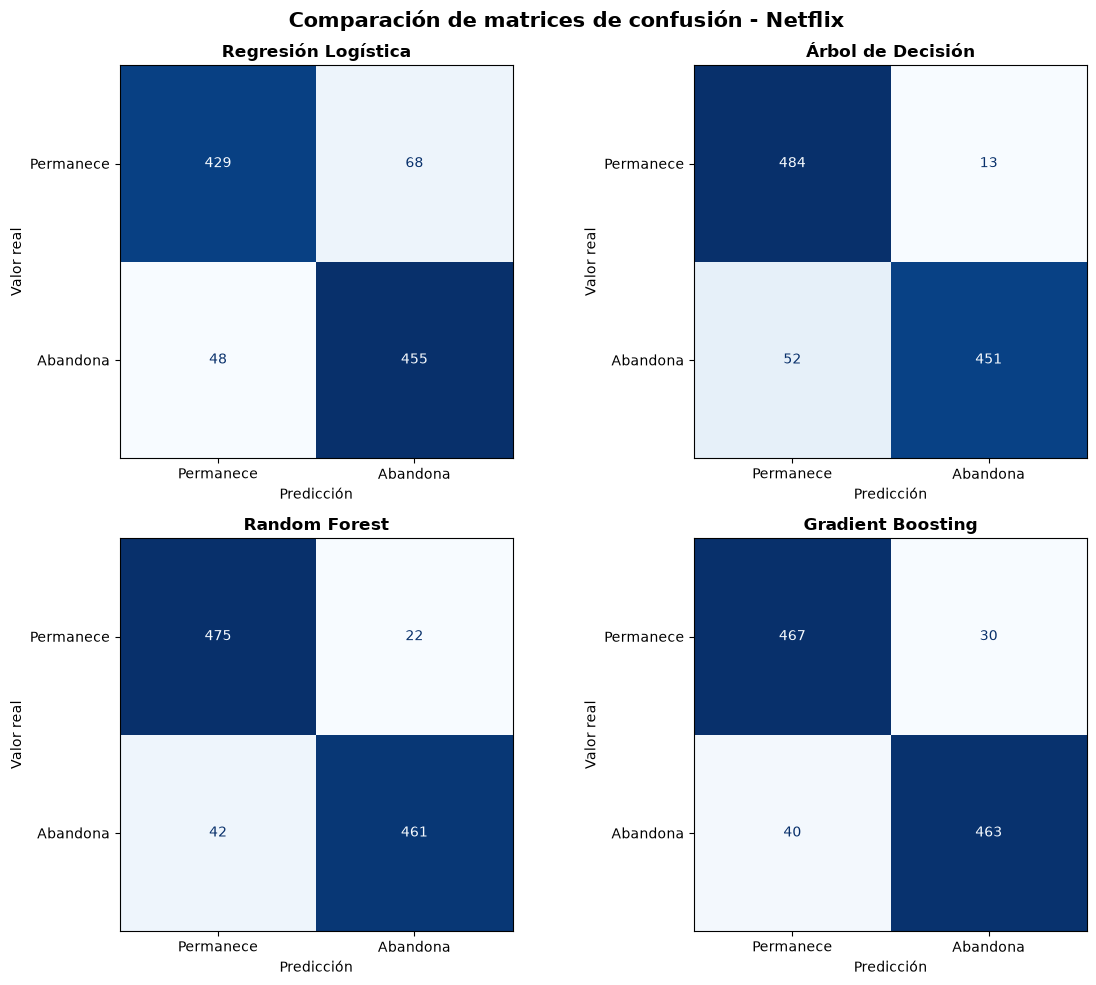

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (nombre, pred) in zip(
    axes.flatten(),
    predicciones_test.items()
):

    matriz = confusion_matrix(
        y_test_churn,
        pred,
        labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Permanece", "Abandona"]
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(nombre, fontweight="bold")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")

plt.suptitle(
    "Comparación de matrices de confusión - Netflix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


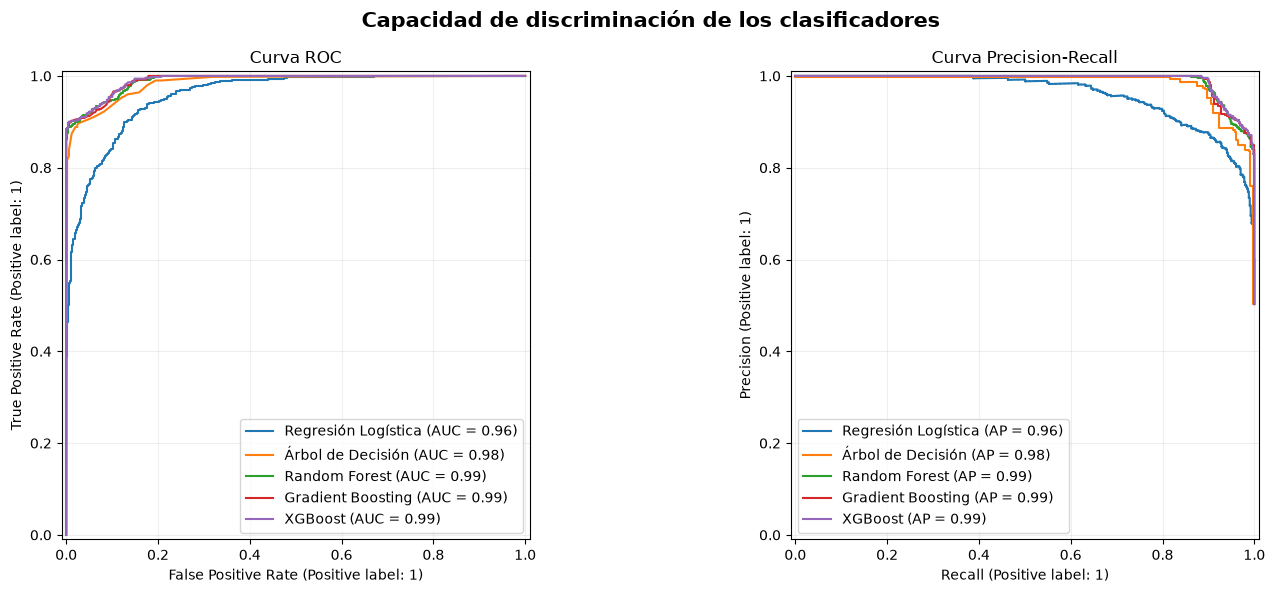

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for nombre, probabilidades in probabilidades_test.items():

    RocCurveDisplay.from_predictions(
        y_test_churn,
        probabilidades,
        name=nombre,
        ax=axes[0]
    )

    PrecisionRecallDisplay.from_predictions(
        y_test_churn,
        probabilidades,
        name=nombre,
        ax=axes[1]
    )

axes[0].set_title("Curva ROC")
axes[0].grid(alpha=0.2)

axes[1].set_title("Curva Precision-Recall")
axes[1].grid(alpha=0.2)

plt.suptitle(
    "Capacidad de discriminación de los clasificadores",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


MODELO: XGBoost

IMPORTANCIA POR PERMUTACIÓN


,Variable,Importancia,Desviación
2,avg_watch_time_per_day,0.2192,0.0181
0,watch_hours,0.1173,0.0095
1,last_login_days,0.1084,0.0118
4,subscription_type_Basic,0.0629,0.0048
3,number_of_profiles,0.0592,0.0117
6,subscription_type_Standard,-0.0004,0.0008
5,subscription_type_Premium,-0.0030,0.0015


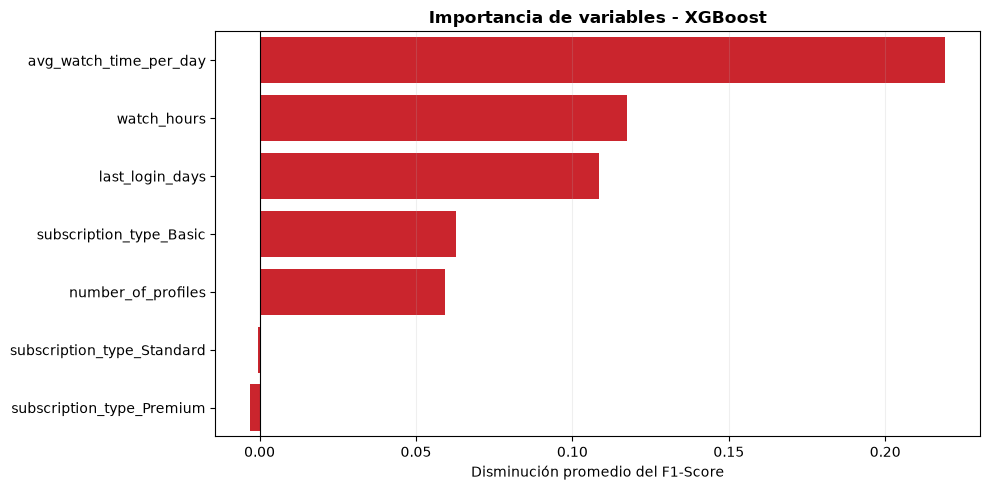

In [47]:
from sklearn.inspection import permutation_importance

importancia = permutation_importance(
    modelo_ganador,
    X_test_churn[columnas_finales],
    y_test_churn,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

tabla_importancia = pd.DataFrame({
    "Variable": columnas_finales,
    "Importancia": importancia.importances_mean,
    "Desviación": importancia.importances_std
}).sort_values(
    "Importancia",
    ascending=False
)

print("MODELO:", mejor_nombre)
print("\nIMPORTANCIA POR PERMUTACIÓN")
display(tabla_importancia.round(4))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=tabla_importancia,
    x="Importancia",
    y="Variable",
    color="#E50914"
)

plt.title(
    f"Importancia de variables - {mejor_nombre}",
    fontweight="bold"
)

plt.xlabel("Disminución promedio del F1-Score")
plt.ylabel("")

plt.axvline(0, color="black", linewidth=0.8)
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

In [48]:
import joblib

# Exportar resultados
resultados_cv.to_csv(
    "comparacion_validacion_cruzada.csv",
    index=False
)

resultados_test.to_csv(
    "comparacion_modelos_churn.csv",
    index=False
)

tabla_importancia.to_csv(
    "importancia_variables_churn.csv",
    index=False
)

# Guardar el modelo con las columnas que espera recibir
joblib.dump(
    {
        "modelo": modelo_ganador,
        "columnas": columnas_finales,
        "escenario": mejor_escenario,
        "nombre_modelo": mejor_nombre
    },
    "modelo_churn_netflix.joblib"
)

print("Resultados y modelo guardados correctamente.")
print("Modelo seleccionado:", mejor_nombre)
print("Escenario seleccionado:", mejor_escenario)
print("Características utilizadas:", columnas_finales)


Resultados y modelo guardados correctamente.
Modelo seleccionado: XGBoost
Escenario seleccionado: Todas las seleccionadas
Características utilizadas: ['watch_hours', 'last_login_days', 'avg_watch_time_per_day', 'number_of_profiles', 'subscription_type_Basic', 'subscription_type_Premium', 'subscription_type_Standard']
